# Capital Adequacy of Every U.S. Bank: CET1, Tier 1, Total and Leverage Ratios against Requirements and Buffers, K-Means Business-Model Peers, and Machine-Learning Forecasts of Capital Shortfalls

**Capital adequacy** is a bank's ability to absorb losses with its own funds and keep operating. It is measured as the ratio of capital to the risk the bank carries: capital over risk-weighted assets for the risk-based ratios, and capital over total exposure for the leverage ratio. Every U.S. bank reports these ratios each quarter, and supervisors sort banks into *prompt corrective action* (PCA) categories by them. Above the minimums sit buffers: a bank that dips into its capital conservation buffer faces automatic limits on dividends and bonuses.

This notebook takes the definition to the data for **all of the roughly 4,300 U.S. banks**, every quarter since 2015:

- **The definition, made concrete.** The capital components (CET1, Additional Tier 1, Tier 2), the four ratios, the PCA thresholds, the conservation buffer and the community bank leverage ratio (CBLR) option for small banks, turned into each bank's *binding headroom*: how many percentage points it stands above the buffer or CBLR threshold that binds it first.
- **The system, today and since 2015.** How many banks sit in each category, how much capital the system holds above its buffers, and how the share of banks inside their buffers moved through COVID and the 2022–2023 rate shock.
- **Business-model peers.** K-means clustering on loan mix, funding, securities, fee income and size, with the number of clusters chosen by silhouette. The clusters are named from their centroids, and a k-nearest-neighbour search finds each bank's ten closest peers. Capital is meaningful only against banks that run the same business.
- **Forecasting shortfalls.** A logistic regression, LightGBM and a GRU recurrent network read eight quarters of each bank's history. They predict which banks will fall inside their buffers within a year, trained to 2021 and tested on 2022–2025. Quantile LightGBM projects the 10th percentile of each bank's headroom a year ahead, turning risk into a projected capital shortfall in dollars.

**Data.** FDIC BankFind call-report financials of every insured U.S. bank, quarterly, 2015 to today (FDIC API).

**Methods.** PCA and buffer arithmetic, K-means with silhouette selection, k-nearest neighbours, logistic regression, LightGBM, GRU sequence classifier, quantile LightGBM, out-of-time AUC, PR-AUC and top-decile capture.

**Key output.** Every bank's capital category and headroom; the system's excess capital; business-model clusters with their capital levels; out-of-time accuracy of three shortfall models; banks most likely to breach their buffers next year and the projected shortfall.

## 1. Capital adequacy: the definition

| Element | What it is |
|---|---|
| **Common Equity Tier 1 (CET1)** | Common shares, retained earnings and (for most banks) accumulated other comprehensive income, minus goodwill, intangibles and certain deferred tax assets |
| **Additional Tier 1** | Perpetual non-cumulative preferred stock and similar instruments |
| **Tier 1** | CET1 + Additional Tier 1 |
| **Tier 2** | Subordinated debt and the allowance for credit losses up to 1.25% of RWA |
| **Risk-weighted assets (RWA)** | Exposures weighted by risk: 0% for Treasuries, 50% for most residential mortgages, 100% for commercial loans, more for some exposures |

| Ratio | Formula | Minimum | + conservation buffer | Well capitalized (PCA) |
|---|---|---|---|---|
| CET1 | CET1 / RWA | 4.5% | 7.0% | 6.5% |
| Tier 1 | Tier 1 / RWA | 6.0% | 8.5% | 8.0% |
| Total capital | (Tier 1 + Tier 2) / RWA | 8.0% | 10.5% | 10.0% |
| Leverage | Tier 1 / average total assets | 4.0% | — | 5.0% |
| CBLR (optional, < USD 10 bn) | Tier 1 / average total assets | — | — | 9.0% (replaces all four) |

**Binding headroom.** For a bank on the risk-based framework, headroom = min(CET1 − 7.0, Tier 1 − 8.5, Total − 10.5, Leverage − 5.0), in percentage points. For a bank that has opted into the CBLR, headroom = Leverage − 9.0 (8.0 in the second half of 2020 and 8.5 in 2021, when the CARES Act temporarily lowered the threshold). A negative headroom means the bank is inside its buffer, or has lost its CBLR eligibility, and faces restrictions on distributions. That **buffer breach** is the event the models forecast. Large banks also carry a stress capital buffer and, for the largest, a G-SIB surcharge; at bank-subsidiary level the 2.5% conservation buffer is the common yardstick.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import torch
import torch.nn as nn
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
FDIC_API = "https://api.fdic.gov/banks/financials"
# CET1 is reported from 2015
FIRST_YEAR = 2015
# example bank for peers and forecasts
BANK_CERT, BANK_NAME = 4214, "BOKF, N.A."
BUFFER = {"cet1": 7.0, "t1": 8.5, "total": 10.5, "lev": 5.0}
WELL = {"cet1": 6.5, "t1": 8.0, "total": 10.0, "lev": 5.0}
ADEQ = {"cet1": 4.5, "t1": 6.0, "total": 8.0, "lev": 4.0}
CBLR_MIN = 9.0
# forecast horizon, quarters
H = 4
SEQ = 8  # GRU reads eight quarters
TRAIN_LAST_OBS, TEST_FIRST_OBS = "2021-12-31", "2022-03-31"
K_RANGE = range(4, 10)

print(
    f"lightgbm {lgb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · torch 2.14.1+cu130 · run on 2026-11-10


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

Every quarterly call report since 2015 is downloaded year by year from the FDIC API, about 300,000 bank-quarters in all. The data include the four regulatory ratios and the CBLR election, plus the balance-sheet and income items that describe each bank's business model and its earnings capacity. Earnings capacity comes from return on assets, net interest margin, charge-offs, noncurrent loans and dividends. Banks on the CBLR report only the leverage ratio, so their risk-based ratios are left empty rather than read as zero.

In [3]:
FIELDS = (
    "CERT,REPDTE,NAME,STALP,ASSET,IDT1CER,RBC1RWAJ,RBCRWAJ,RBC1AAJ,CBLRIND,RBCT1C,RBCT1J,RWAJ,EQ,ROA,NIMY,NTLNLS,NCLNLS,LNLSNET,LNATRES,"
    "LNRECONS,LNRENRES,LNREMULT,LNRERES,LNCI,LNCON,LNAG,SC,DEP,DEPUNA,BRO,NONII,INTINC,EINTEXP,NETINC,EQCDIV,INTANGW"
)


def fetch_year(y):
    rows, offset = [], 0
    while True:
        r = requests.get(
            FDIC_API,
            params={
                "filters": f"REPDTE:[{y}0101 TO {y}1231]",
                "fields": FIELDS,
                "limit": 10_000,
                "offset": offset,
                "sort_by": "CERT",
                "sort_order": "ASC",
            },
            timeout=180,
        )
        r.raise_for_status()
        js = r.json()
        rows += [d["data"] for d in js["data"]]
        offset += 10_000
        if offset >= js["meta"]["total"]:
            break
    return pd.DataFrame(rows).drop(columns="ID", errors="ignore")


this_year = dt.date.today().year
RAW = pd.concat([
    cached(
        f"fdic_all_{y}",
        lambda y=y: fetch_year(y),
        max_age_hours=24 * 7 if y >= this_year - 1 else 24 * 90,
    )
    for y in range(FIRST_YEAR, this_year + 1)
])
D = RAW.copy()
D["date"] = pd.to_datetime(D.REPDTE.astype(str)) + pd.offsets.QuarterEnd(0)
num = [c for c in D.columns if c not in ("NAME", "STALP", "REPDTE", "date")]
D[num] = D[num].apply(pd.to_numeric, errors="coerce")
D = (
    D.sort_values(["CERT", "date"])
    .drop_duplicates(["CERT", "date"])
    .reset_index(drop=True)
)
D["cblr"] = D.CBLRIND.fillna(0).eq(1)
D["cet1"] = D.IDT1CER.where(~D.cblr & (D.IDT1CER > 0))
D["t1"] = D.RBC1RWAJ.where(~D.cblr & (D.RBC1RWAJ > 0))
D["total"] = D.RBCRWAJ.where(~D.cblr & (D.RBCRWAJ > 0))
D["lev"] = D.RBC1AAJ.where(D.RBC1AAJ > 0)
D = D[D.lev.notna() & (D.ASSET > 0)]
for c in ["cet1", "t1", "total", "lev"]:
    # trust-only and de novo banks report extreme ratios
    D[c] = D[c].clip(upper=60)
LAST = D.date.max()
print(
    f"{len(D):,} bank-quarters, {D.CERT.nunique():,} banks,"
    f" {D.date.min():%Y-%m} to {LAST:%Y-%m}; banks at the latest quarter:"
    f" {(D.date == LAST).sum():,}"
)

239,541 bank-quarters, 6,576 banks, 2015-03 to 2026-06; banks at the latest quarter: 4,296


In [4]:
def cblr_threshold(dates):
    """
    CBLR threshold, temporarily lowered by the CARES Act: 8% from Q2 2020, 8.5%
    in 2021, 9% otherwise.
    """
    return np.where(
        (dates >= "2020-06-30") & (dates <= "2020-12-31"),
        8.0,
        np.where(dates.dt.year == 2021, 8.5, CBLR_MIN),
    )


def capital_status(d):
    rb = pd.concat(
        [
            d.cet1 - BUFFER["cet1"],
            d.t1 - BUFFER["t1"],
            d.total - BUFFER["total"],
            d.lev - BUFFER["lev"],
        ],
        axis=1,
        keys=["CET1", "Tier 1", "Total", "Leverage"],
    )
    thr = cblr_threshold(d.date)
    head = np.where(d.cblr, d.lev - thr, rb.min(axis=1))
    binding = np.where(d.cblr, "CBLR leverage", rb.idxmin(axis=1))
    # a bank that reports no risk-based ratio is judged on leverage
    big = lambda c: d[c].fillna(999)
    well = np.where(
        d.cblr,
        d.lev >= thr,
        (big("cet1") >= WELL["cet1"])
        & (big("t1") >= WELL["t1"])
        & (big("total") >= WELL["total"])
        & (d.lev >= WELL["lev"]),
    )
    adeq = np.where(
        d.cblr,
        d.lev >= ADEQ["lev"],
        (big("cet1") >= ADEQ["cet1"])
        & (big("t1") >= ADEQ["t1"])
        & (big("total") >= ADEQ["total"])
        & (d.lev >= ADEQ["lev"]),
    )
    cat = np.where(
        well,
        "Well capitalized",
        np.where(adeq, "Adequately capitalized", "Undercapitalized or worse"),
    )
    return pd.DataFrame(
        {"headroom": head, "binding": binding, "category": cat}, index=d.index
    )


D = D.join(capital_status(D))
D["breach"] = D.headroom < 0
# USD thousands behind the binding ratio
D["base"] = np.where(
    (D.binding.isin(["CET1", "Tier 1", "Total"])) & D.RWAJ.gt(0),
    D.RWAJ,
    D.ASSET,
)
D["excess_usd"] = D.headroom / 100 * D.base
L = D[D.date == LAST]
SUMMARY = pd.DataFrame({
    "banks": L.groupby("category").size(),
    "assets (USD bn)": L.groupby("category").ASSET.sum() / 1e6,
})
SUMMARY.loc["of which: inside buffer / below CBLR"] = [
    L.breach.sum(),
    L[L.breach].ASSET.sum() / 1e6,
]
SUMMARY.loc["of which: on the CBLR"] = [
    L.cblr.sum(),
    L[L.cblr].ASSET.sum() / 1e6,
]
print(
    f"At {LAST:%Y-%m-%d}: system capital above buffers USD"
    f" {L.excess_usd.clip(lower=0).sum() / 1e6:,.0f} bn; shortfall of banks"
    " inside their buffers USD"
    f" {-L.excess_usd.clip(upper=0).sum() / 1e6:,.2f} bn"
)
print("Binding constraint:", L.binding.value_counts().to_dict())
SUMMARY.style.format({"banks": "{:,.0f}", "assets (USD bn)": "{:,.0f}"})

At 2026-06-30: system capital above buffers USD 765 bn; shortfall of banks inside their buffers USD 0.06 bn
Binding constraint: {'CBLR leverage': 1814, 'Total': 1363, 'Leverage': 1101, 'Tier 1': 10, 'CET1': 8}


,banks,assets (USD bn)
category,,
Adequately capitalized,28,12
Undercapitalized or worse,5,1
Well capitalized,"4,263","26,478"
of which: inside buffer / below CBLR,40,17
of which: on the CBLR,"1,814",935


## 4. The system since 2015

The share of banks inside their buffers, and the median ratios, show how capital moved through:
- **COVID in 2020.** Deposits flooded in and swelled total assets, which pressed leverage ratios, and the CBLR was temporarily lowered to 8%.
- **The 2022–2023 rate shock.** Unrealised securities losses hit the equity of banks that include accumulated other comprehensive income, and earnings came under pressure.

In [5]:
HIST = D.groupby("date").agg(
    banks=("CERT", "size"),
    breach_share=("breach", "mean"),
    cblr_share=("cblr", "mean"),
    median_cet1=("cet1", "median"),
    median_lev=("lev", "median"),
    median_headroom=("headroom", "median"),
)
HIST["new breaches"] = (
    D.assign(
        new=D.breach
        & ~D.groupby("CERT").breach.shift(1).fillna(False).astype(bool)
    )
    .groupby("date")
    .new.sum()
)
# no previous quarter to compare with
HIST.loc[HIST.index[0], "new breaches"] = np.nan
print(
    f"Banks inside buffer: peak {HIST.breach_share.max():.2%}"
    f" ({HIST.breach_share.idxmax():%Y-%m}), latest"
    f" {HIST.breach_share.iloc[-1]:.2%}; CBLR users at the latest quarter"
    f" {HIST.cblr_share.iloc[-1]:.0%}"
)
HIST.iloc[::4].style.format({
    "breach_share": "{:.2%}",
    "cblr_share": "{:.0%}",
    "median_cet1": "{:.2f}",
    "median_lev": "{:.2f}",
    "median_headroom": "{:.2f}",
})

Banks inside buffer: peak 3.65% (2022-03), latest 0.93%; CBLR users at the latest quarter 42%


,banks,breach_share,cblr_share,median_cet1,median_lev,median_headroom,new breaches
date,,,,,,,
2015-03-31 00:00:00,6478,2.08%,0%,15.35,10.33,4.67,nan
2016-03-31 00:00:00,6175,1.64%,0%,15.16,10.43,4.63,20.000000
2017-03-31 00:00:00,5907,1.24%,0%,15.09,10.50,4.67,16.000000
2018-03-31 00:00:00,5657,0.85%,0%,15.14,10.66,4.80,12.000000
2019-03-31 00:00:00,5411,0.59%,0%,15.42,10.91,5.06,10.000000
2020-03-31 00:00:00,5165,0.58%,33%,14.53,10.94,3.90,17.000000
2021-03-31 00:00:00,5027,2.29%,38%,14.92,10.07,3.56,99.000000
2022-03-31 00:00:00,4844,3.65%,35%,14.75,9.92,3.33,145.000000
2023-03-31 00:00:00,4723,1.08%,36%,14.19,10.37,3.52,27.000000


## 5. Business-model peers: K-means and nearest neighbours

A 9% leverage ratio is generous for a farm lender and thin for a bank that trades securities, so capital needs to be read against the right peers. Banks are clustered on what they do:
- **Lending mix:** the shares of construction and commercial real estate (CRE), residential, C&I, consumer and agricultural loans in total loans.
- **Balance sheet:** loans and securities as shares of assets.
- **Funding:** uninsured and brokered deposits.
- **Fee business:** non-interest income relative to revenue.
- **Size:** log assets.

Features are standardised and *k* is chosen by the silhouette score. Each cluster is named after the two features whose centroid is furthest above the average.

In [6]:
def business_features(d):
    gross = (d.LNLSNET + d.LNATRES.fillna(0)).where(lambda s: s > 0)
    rev = (d.INTINC - d.EINTEXP + d.NONII).where(lambda s: s > 0)
    f = pd.DataFrame(
        {
            "CRE & construction": (
                (d.LNRECONS + d.LNRENRES + d.LNREMULT) / gross
            ),
            "residential": d.LNRERES / gross,
            "C&I": d.LNCI / gross,
            "consumer": d.LNCON / gross,
            "agricultural": d.LNAG.fillna(0) / gross,
            "loans / assets": d.LNLSNET / d.ASSET,
            "securities / assets": d.SC / d.ASSET,
            "uninsured deposits": d.DEPUNA / d.DEP,
            "brokered deposits": d.BRO / d.DEP,
            "fee income share": d.NONII / rev,
            "log assets": np.log(d.ASSET),
        },
        index=d.index,
    )
    return f.clip(lower=-1, upper=5)


BF = (
    business_features(L.set_index("CERT"))
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
# leave out trust banks and other non-lenders
BF = BF[(BF["loans / assets"] > 0.05)]
sb = StandardScaler().fit(BF)
Z = sb.transform(BF)
sil = {}
for k in K_RANGE:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    sil[k] = silhouette_score(
        Z, km.labels_, sample_size=min(3000, len(Z)), random_state=SEED
    )
K_BEST = max(sil, key=sil.get)
KM = KMeans(K_BEST, n_init=20, random_state=SEED).fit(Z)
cent = pd.DataFrame(KM.cluster_centers_, columns=BF.columns)
names = {
    i: " + ".join(cent.loc[i].sort_values(ascending=False).index[:2])
    for i in cent.index
}
BF["cluster"] = pd.Series(KM.labels_, index=BF.index).map(names)
LB = L.set_index("CERT").join(BF["cluster"], how="inner")
CLUST = (
    LB.groupby("cluster")
    .agg(
        banks=("NAME", "size"),
        median_assets_bn=("ASSET", lambda s: s.median() / 1e6),
        cblr_share=("cblr", "mean"),
        median_cet1=("cet1", "median"),
        median_leverage=("lev", "median"),
        median_headroom=("headroom", "median"),
        inside_buffer=("breach", "mean"),
        median_roa=("ROA", "median"),
    )
    .sort_values("banks", ascending=False)
)
print(
    "Silhouette by k:",
    {k: round(v, 3) for k, v in sil.items()},
    f"→ k = {K_BEST}",
)
CLUST.style.format({
    "median_assets_bn": "{:.2f}",
    "cblr_share": "{:.0%}",
    "median_cet1": "{:.2f}",
    "median_leverage": "{:.2f}",
    "median_headroom": "{:.2f}",
    "inside_buffer": "{:.1%}",
    "median_roa": "{:.2f}",
})

Silhouette by k: {4: 0.157, 5: 0.177, 6: 0.189, 7: 0.194, 8: 0.199, 9: 0.179} → k = 8


,banks,median_assets_bn,cblr_share,median_cet1,median_leverage,median_headroom,inside_buffer,median_roa
cluster,,,,,,,,
CRE & construction + loans / assets,1138,0.42,47%,13.83,10.82,3.42,1.4%,1.26
residential + loans / assets,811,0.25,46%,15.89,10.98,4.00,0.9%,1.01
uninsured deposits + CRE & construction,691,2.54,18%,13.18,10.48,3.56,0.0%,1.25
securities / assets + consumer,684,0.22,51%,20.01,11.41,4.50,1.3%,1.16
agricultural + securities / assets,511,0.17,59%,15.39,11.53,3.89,0.4%,1.43
C&I + brokered deposits,194,0.73,31%,12.85,10.88,3.28,2.1%,1.17
fee income share + brokered deposits,113,0.69,29%,15.46,10.40,3.83,0.9%,1.22
consumer + brokered deposits,52,1.35,27%,15.35,11.67,5.37,1.9%,1.66


In [7]:
nn_ = NearestNeighbors(n_neighbors=11).fit(Z)
i_bank = BF.index.get_loc(BANK_CERT)
dist, ind = nn_.kneighbors(Z[[i_bank]])
PEERS = LB.loc[
    BF.index[ind[0]],
    [
        "NAME",
        "STALP",
        "ASSET",
        "cluster",
        "cet1",
        "t1",
        "total",
        "lev",
        "headroom",
        "ROA",
    ],
].assign(distance=dist[0])
PEERS["ASSET"] = PEERS.ASSET / 1e6
pct = (
    PEERS.iloc[1:][["cet1", "lev", "headroom"]].lt(
        PEERS.iloc[0][["cet1", "lev", "headroom"]]
    )
).mean()
print(
    f"{BANK_NAME} is in cluster '{BF.loc[BANK_CERT, 'cluster']}'. Against its"
    f" ten nearest peers it ranks above {pct['cet1']:.0%} on CET1,"
    f" {pct['lev']:.0%} on leverage and {pct['headroom']:.0%} on headroom."
)
PEERS.rename(columns={"ASSET": "assets (USD bn)"}).style.format({
    "assets (USD bn)": "{:,.1f}",
    "cet1": "{:.2f}",
    "t1": "{:.2f}",
    "total": "{:.2f}",
    "lev": "{:.2f}",
    "headroom": "{:.2f}",
    "ROA": "{:.2f}",
    "distance": "{:.2f}",
})

BOKF, N.A. is in cluster 'uninsured deposits + CRE & construction'. Against its ten nearest peers it ranks above 30% on CET1, 30% on leverage and 60% on headroom.


/usr/local/lib/python3.13/site-packages/pandas/core/computation/expressions.py:83: RuntimeWarning: invalid value encountered in less
  return op(left_op, right_op)


,NAME,STALP,assets (USD bn),cluster,cet1,t1,total,lev,headroom,ROA,distance
CERT,,,,,,,,,,,
4214,BOKF NATIONAL ASSN,OK,53.0,uninsured deposits + CRE & construction,12.29,12.29,14.17,9.29,3.67,1.23,0.00
8273,UMB BANK NATIONAL ASSN,MO,71.9,uninsured deposits + CRE & construction,11.75,11.75,12.62,8.89,2.12,1.39,1.29
6600,FIRST FINANCIAL BANK,OH,22.4,uninsured deposits + CRE & construction,12.77,12.78,14.05,9.78,3.55,1.56,1.37
17534,KEYBANK NATIONAL ASSN,OH,188.6,uninsured deposits + CRE & construction,12.27,12.27,14.05,9.92,3.55,1.28,1.52
12441,HANCOCK WHITNEY BANK,MS,36.3,uninsured deposits + CRE & construction,12.86,12.86,14.06,10.59,3.56,1.01,1.56
8018,GROVE BANK&TRUST,FL,1.4,uninsured deposits + CRE & construction,15.22,15.22,16.47,9.96,4.96,0.68,1.64
19333,REPUBLIC BANK OF CHICAGO,IL,2.6,uninsured deposits + CRE & construction,nan,nan,nan,12.57,3.57,1.36,1.67
5510,FROST BANK,TX,54.0,uninsured deposits + CRE & construction,14.42,14.42,15.42,9.08,4.08,1.31,1.78
6384,PNC BANK NATIONAL ASSN,DE,609.8,uninsured deposits + CRE & construction,11.20,11.20,12.82,8.98,2.32,1.32,1.84


## 6. Forecasting capital shortfalls

**Event.** A bank that is outside its buffer today falls inside it (or below the CBLR threshold) in any of the next four quarters.

**Features.** Each bank-quarter carries:
- *Capital:* today's binding headroom, its change over the last four quarters, the CBLR flag and the type of binding ratio.
- *Earnings and asset quality:* ROA, net interest margin, the net charge-off rate, noncurrent loans, allowance coverage and the dividend payout.
- *Balance sheet:* loan and asset growth, the business-model shares and size.

**Models.**
- **Logistic regression** on the current quarter.
- **LightGBM** on the current quarter.
- **GRU** reading the last eight quarters, so it can see trends and deterioration that a single snapshot misses.

Training uses observations to December 2021, whose outcomes run to the end of 2022. Testing uses observations from March 2022 onward, through the rate shock, out of time.

**Projected shortfall.** Quantile LightGBM predicts the median and the 10th percentile of each bank's headroom four quarters ahead. A negative 10th percentile, multiplied by the base behind the binding ratio, is the bank's projected shortfall in a bad year.

In [8]:
g = D.groupby("CERT")
D["quarters_seen"] = g.cumcount()
gap = g.date.diff().dt.days
D["consecutive"] = gap.between(85, 95) | D.quarters_seen.eq(0)
D["headroom_chg4"] = D.headroom - g.headroom.shift(4)
D["asset_growth"] = D.ASSET / g.ASSET.shift(4) - 1
D["loan_growth"] = D.LNLSNET / g.LNLSNET.shift(4) - 1
# YTD charge-offs, annualised
D["nco_rate"] = (
    D.NTLNLS / D.LNLSNET.where(D.LNLSNET > 0) * (4 / D.date.dt.quarter)
)
D["noncurrent"] = D.NCLNLS / D.LNLSNET.where(D.LNLSNET > 0)
D["coverage"] = D.LNATRES / D.NCLNLS.where(D.NCLNLS > 0)
D["payout"] = (D.EQCDIV / D.NETINC.where(D.NETINC > 0)).clip(0, 3)
D["log_assets"] = np.log(D.ASSET)
D["binding_rb"] = D.binding.isin(["CET1", "Tier 1", "Total"]).astype(float)
bf_all = business_features(D)
for c in [
    "CRE & construction",
    "C&I",
    "consumer",
    "agricultural",
    "securities / assets",
    "uninsured deposits",
    "fee income share",
]:
    D[c] = bf_all[c]
FEATS = [
    "headroom",
    "headroom_chg4",
    "cblr",
    "binding_rb",
    "ROA",
    "NIMY",
    "nco_rate",
    "noncurrent",
    "coverage",
    "payout",
    "asset_growth",
    "loan_growth",
    "CRE & construction",
    "C&I",
    "consumer",
    "agricultural",
    "securities / assets",
    "uninsured deposits",
    "fee income share",
    "log_assets",
]
D["cblr"] = D.cblr.astype(float)
D[FEATS] = D[FEATS].replace([np.inf, -np.inf], np.nan)
for c in [
    "asset_growth",
    "loan_growth",
    "nco_rate",
    "noncurrent",
    "coverage",
    "headroom_chg4",
    "ROA",
    "NIMY",
]:
    lo, hi = D[c].quantile([0.005, 0.995])
    D[c] = D[c].clip(lo, hi)
fut = pd.concat([g.breach.shift(-k) for k in range(1, H + 1)], axis=1)
D["event"] = fut.max(axis=1).where(fut.notna().all(axis=1))
D["headroom_ahead"] = g.headroom.shift(-H)
M = D[~D.breach & D.event.notna() & D[FEATS].notna().all(axis=1)].copy()
M["event"] = M.event.astype(float)
TR, TE = M[M.date <= TRAIN_LAST_OBS], M[M.date >= TEST_FIRST_OBS]
print(
    f"Model sample: train {len(TR):,} bank-quarters ({TR.event.mean():.2%}"
    f" events), test {len(TE):,} ({TE.event.mean():.2%} events,"
    f" {TE[TE.event == 1].CERT.nunique()} banks)"
)

Model sample: train 77,431 bank-quarters (2.14% events), test 50,270 (1.85% events, 287 banks)


In [9]:
sx = StandardScaler().fit(TR[FEATS])
LOGIT = LogisticRegression(C=0.3, max_iter=3000).fit(
    sx.transform(TR[FEATS]), TR.event
)
GBM = lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
).fit(TR[FEATS], TR.event)
# GRU: eight consecutive quarters of standardised features ending at each
# modelled bank-quarter
DX = D[FEATS].copy()
DX = pd.DataFrame(
    np.nan_to_num(sx.transform(DX.fillna(TR[FEATS].median()))),
    index=D.index,
    columns=FEATS,
)
run_ok = (
    D.consecutive.astype(int)
    .groupby(D.CERT)
    .transform(lambda s: s.rolling(SEQ, min_periods=SEQ).sum())
    .eq(SEQ)
)
pos = {ix: k for k, ix in enumerate(D.index)}
ARR = DX.values.astype(np.float32)


def seqs(frame):
    keep = frame.index[run_ok.reindex(frame.index).fillna(False).values]
    idx = np.array([pos[i] for i in keep])
    win = np.stack([ARR[idx - SEQ + 1 + k] for k in range(SEQ)], axis=1)
    return win, frame.loc[keep, "event"].values.astype(np.float32), keep


class SeqGRU(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.gru, self.out = nn.GRU(n, 32, batch_first=True), nn.Linear(32, 1)

    def forward(self, x):
        return self.out(self.gru(x)[0][:, -1]).squeeze(-1)


Xs, ys, _ = seqs(TR)
torch.manual_seed(SEED)
GRU = SeqGRU(len(FEATS))
opt = torch.optim.Adam(GRU.parameters(), lr=2e-3, weight_decay=1e-5)
lossf = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(min(20.0, (1 - ys.mean()) / ys.mean()))
)
Xt, yt = torch.tensor(Xs), torch.tensor(ys)
gen = torch.Generator().manual_seed(SEED)
t0 = time.time()
for ep in range(6):
    perm = torch.randperm(len(Xt), generator=gen)
    for b in range(0, len(Xt), 512):
        i_ = perm[b : b + 512]
        loss = lossf(GRU(Xt[i_]), yt[i_])
        opt.zero_grad()
        loss.backward()
        opt.step()
print(
    f"GRU trained on {len(Xs):,} eight-quarter sequences in"
    f" {time.time() - t0:.0f} s"
)


def predict_all(frame):
    out = pd.DataFrame(
        {
            "Logistic": LOGIT.predict_proba(sx.transform(frame[FEATS]))[:, 1],
            "LightGBM": GBM.predict_proba(frame[FEATS])[:, 1],
        },
        index=frame.index,
    )
    w, _, keep = seqs(frame)
    with torch.no_grad():
        out.loc[keep, "GRU"] = torch.sigmoid(GRU(torch.tensor(w))).numpy()
    return out


P_TE = predict_all(TE)
ev = TE.event
rows = []
for m in ["Logistic", "LightGBM", "GRU"]:
    ok = P_TE[m].notna()
    p, y_ = P_TE.loc[ok, m], ev[ok]
    top = p >= p.quantile(0.9)
    rows.append((
        m,
        ok.mean(),
        roc_auc_score(y_, p),
        average_precision_score(y_, p),
        y_[top].sum() / y_.sum(),
        brier_score_loss(y_, p),
    ))
ok_all = P_TE.notna().all(axis=1)
for m, base in [("Headroom only (lower = riskier)", -TE.headroom)]:
    rows.append((
        m,
        1.0,
        roc_auc_score(ev, base),
        average_precision_score(ev, base),
        ev[base >= base.quantile(0.9)].sum() / ev.sum(),
        np.nan,
    ))
FCST = pd.DataFrame(
    rows,
    columns=[
        "model",
        "coverage of test sample",
        "AUC",
        "PR-AUC",
        "events in top decile",
        "Brier",
    ],
)
FCST.style.format({
    "coverage of test sample": "{:.0%}",
    "AUC": "{:.3f}",
    "PR-AUC": "{:.3f}",
    "events in top decile": "{:.0%}",
    "Brier": "{:.4f}",
})

GRU trained on 62,418 eight-quarter sequences in 4 s


,model,coverage of test sample,AUC,PR-AUC,events in top decile,Brier
0,Logistic,100%,0.904,0.214,69%,0.0186
1,LightGBM,100%,0.919,0.210,77%,0.0183
2,GRU,100%,0.905,0.180,70%,0.1113
3,Headroom only (lower = riskier),100%,0.910,0.237,76%,nan


In [10]:
gain = pd.Series(GBM.booster_.feature_importance("gain"), index=FEATS)
print(
    "LightGBM gain importance:",
    ", ".join(
        f"{k} {v:.0%}"
        for k, v in (
            (gain / gain.sum()).sort_values(ascending=False).head(8).items()
        )
    ),
)
# projected headroom a year ahead: quantile LightGBM on the full history with
# known outcomes
QM = D[D.headroom_ahead.notna() & D[FEATS].notna().all(axis=1)]
QMOD = {
    q: (
        lgb.LGBMRegressor(
            objective="quantile",
            alpha=q,
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=200,
            random_state=SEED,
            verbose=-1,
        ).fit(QM[FEATS], QM.headroom_ahead)
    )
    for q in [0.1, 0.5]
}
NOW = D[(D.date == LAST) & D[FEATS].notna().all(axis=1)].copy()
NOW["p_breach (LightGBM)"] = GBM.predict_proba(NOW[FEATS])[:, 1]
NOW["headroom q50 in 1y"] = QMOD[0.5].predict(NOW[FEATS])
NOW["headroom q10 in 1y"] = QMOD[0.1].predict(NOW[FEATS])
NOW["shortfall q10 (USD m)"] = (
    (-NOW["headroom q10 in 1y"]).clip(lower=0) / 100 * NOW.base / 1e3
)
OUTLOOK = pd.Series({
    "banks scored": len(NOW),
    "inside buffer today": int(NOW.breach.sum()),
    "expected new breaches next year (sum of probabilities, banks outside today)": (
        NOW.loc[~NOW.breach, "p_breach (LightGBM)"].sum()
    ),
    "banks with q10 headroom < 0 next year": int(
        (NOW["headroom q10 in 1y"] < 0).sum()
    ),
    "projected shortfall at q10 (USD m)": NOW["shortfall q10 (USD m)"].sum(),
})
WATCH = NOW[~NOW.breach].nlargest(12, "p_breach (LightGBM)")[[
    "NAME",
    "STALP",
    "ASSET",
    "binding",
    "headroom",
    "p_breach (LightGBM)",
    "headroom q50 in 1y",
    "headroom q10 in 1y",
    "shortfall q10 (USD m)",
]]
WATCH["ASSET"] = WATCH.ASSET / 1e6
b_ = NOW[NOW.CERT == BANK_CERT]
if len(b_):
    print(
        f"{BANK_NAME}: headroom {b_.headroom.iloc[0]:.2f} pp"
        f" ({b_.binding.iloc[0]} binding), p(breach within a year)"
        f" {b_['p_breach (LightGBM)'].iloc[0]:.2%}, headroom in a year q50"
        f" {b_['headroom q50 in 1y'].iloc[0]:.2f} / q10"
        f" {b_['headroom q10 in 1y'].iloc[0]:.2f} pp"
    )
display(OUTLOOK.to_frame("value").style.format("{:,.1f}"))
WATCH.rename(columns={"ASSET": "assets (USD bn)"}).style.format({
    "assets (USD bn)": "{:,.2f}",
    "headroom": "{:.2f}",
    "p_breach (LightGBM)": "{:.1%}",
    "headroom q50 in 1y": "{:.2f}",
    "headroom q10 in 1y": "{:.2f}",
    "shortfall q10 (USD m)": "{:,.1f}",
})

LightGBM gain importance: headroom 38%, cblr 7%, log_assets 6%, consumer 4%, securities / assets 4%, CRE & construction 4%, agricultural 4%, fee income share 4%


BOKF, N.A.: headroom 3.67 pp (Total binding), p(breach within a year) 0.04%, headroom in a year q50 3.71 / q10 2.63 pp


,value
banks scored,"3,583.0"
inside buffer today,21.0
"expected new breaches next year (sum of probabilities, banks outside today)",89.9
banks with q10 headroom < 0 next year,83.0
projected shortfall at q10 (USD m),37.8


,NAME,STALP,assets (USD bn),binding,headroom,p_breach (LightGBM),headroom q50 in 1y,headroom q10 in 1y,shortfall q10 (USD m)
123846,ALL CAPITAL BANK,OK,0.18,CBLR leverage,0.52,82.4%,0.63,-0.11,0.2
192551,VIKING BANK NATIONAL ASSN,MN,0.33,CBLR leverage,0.19,80.0%,0.50,-0.15,0.5
55755,FIRST TRI COUNTY BANK,NE,0.08,CBLR leverage,0.07,79.6%,0.73,-0.05,0.0
124718,PRINCEVILLE STATE BANK,IL,0.12,CBLR leverage,0.23,77.7%,0.71,-0.22,0.3
145811,COMMUNITY STATE BANK,OK,0.39,CBLR leverage,0.05,76.6%,0.59,0.04,0.0
21674,FIRST NB OF ASPERMONT,TX,0.13,CBLR leverage,0.07,76.5%,0.64,0.06,0.0
107806,RIVERWIND BANK,AR,0.17,CBLR leverage,0.09,76.5%,0.60,-0.05,0.1
18825,BANK OF BRODHEAD,WI,0.42,CBLR leverage,0.20,71.5%,0.60,-0.01,0.0
90602,ALLIANCE BANK,WI,0.27,CBLR leverage,0.02,70.5%,0.75,-0.21,0.5
22961,FIRST NATIONAL BANK OF EVANT,TX,0.20,CBLR leverage,0.83,70.0%,0.95,0.15,0.0


## 7. Charts and dashboard

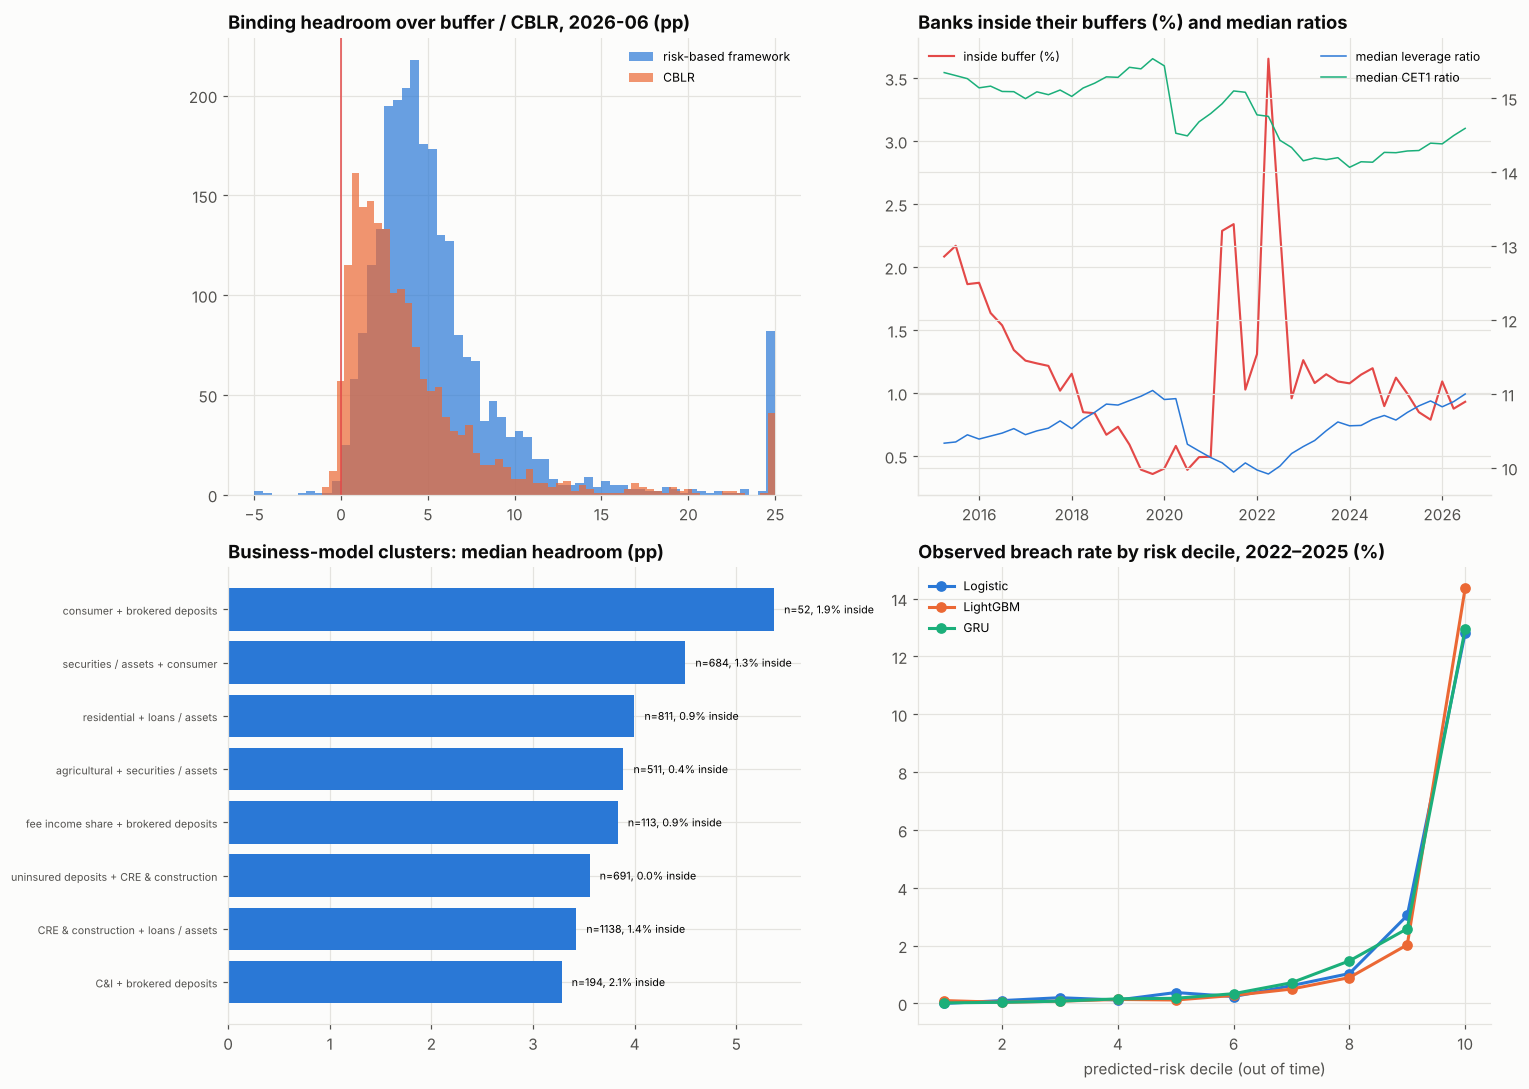

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
h = L.headroom.clip(-5, 25)
a.hist(
    h[~L.cblr],
    bins=60,
    alpha=0.7,
    color=PALETTE[0],
    label="risk-based framework",
)
a.hist(h[L.cblr], bins=60, alpha=0.7, color=PALETTE[1], label="CBLR")
a.axvline(0, color=PALETTE[7], lw=1)
a.set_title(f"Binding headroom over buffer / CBLR, {LAST:%Y-%m} (pp)")
a.legend(fontsize=8)
a = ax[0, 1]
a.plot(
    HIST.index,
    HIST.breach_share * 100,
    color=PALETTE[7],
    lw=1.4,
    label="inside buffer (%)",
)
a2 = a.twinx()
a2.plot(
    HIST.index,
    HIST.median_lev,
    color=PALETTE[0],
    lw=1,
    label="median leverage ratio",
)
a2.plot(
    HIST.index,
    HIST.median_cet1,
    color=PALETTE[2],
    lw=1,
    label="median CET1 ratio",
)
a.set_title("Banks inside their buffers (%) and median ratios")
a.legend(loc="upper left", fontsize=8)
a2.legend(loc="upper right", fontsize=8)
a = ax[1, 0]
cl = CLUST.sort_values("median_headroom")
a.barh(cl.index, cl.median_headroom, color=PALETTE[0])
for i_, (nm, r) in enumerate(cl.iterrows()):
    a.text(
        r.median_headroom + 0.1,
        i_,
        f"n={int(r.banks)}, {r.inside_buffer:.1%} inside",
        va="center",
        fontsize=7,
    )
a.set_title("Business-model clusters: median headroom (pp)")
a.tick_params(axis="y", labelsize=7)
a = ax[1, 1]
for j, m in enumerate(["Logistic", "LightGBM", "GRU"]):
    ok = P_TE[m].notna()
    p = P_TE.loc[ok, m]
    qs = pd.qcut(p.rank(method="first"), 10, labels=False)
    a.plot(
        range(1, 11),
        ev[ok].groupby(qs).mean().values * 100,
        marker="o",
        color=PALETTE[j],
        label=m,
    )
a.set_xlabel("predicted-risk decile (out of time)")
a.set_title("Observed breach rate by risk decile, 2022–2025 (%)")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_capital_adequacy_overview")
plt.show()

In [12]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Share of banks inside their buffers (%)",
        "Out-of-time model accuracy (AUC)",
    ),
)
dash.add_trace(
    go.Scatter(
        x=HIST.index,
        y=HIST.breach_share * 100,
        name="inside buffer",
        line=dict(color=PALETTE[7]),
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(x=FCST.model, y=FCST.AUC, name="AUC", marker_color=PALETTE[0]), 1, 2
)
dash.update_layout(
    height=520,
    width=1400,
    template="simple_white",
    title="Capital adequacy of U.S. banks",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

*Call reports are re-downloaded when a new quarter is published and the network is seeded; figures shift slightly with each update.*

**The system at June 2026.** The FDIC data cover 4,296 insured banks holding USD 26.5 trillion of assets.

| Category | Banks | Assets (USD bn) |
|---|---|---|
| Well capitalized | 4,263 | 26,478 |
| Adequately capitalized | 28 | 12 |
| Undercapitalized or worse | 5 | 0.5 |
| *Inside their buffer, or below the CBLR threshold* | *40* | *17* |
| *On the community bank leverage ratio* | *1,814 (42%)* | *935* |

- **U.S. banks hold about USD 765 billion of capital above their buffers.** The 40 banks inside them are small, with USD 17 billion of assets in all. Restoring their buffers would take about USD 60 million.
- **What binds is not CET1.**
  - *CBLR banks:* for the 1,814 banks on the CBLR, the 9% leverage ratio binds.
  - *Risk-based banks:* among the rest, the 10.5% total-capital buffer binds for 1,363 banks and the 5% leverage ratio for 1,101. CET1 or Tier 1 binds for only 18.
  - *Why:* the median bank's CET1 ratio is above 14%, and its Tier 2 capital is thin. U.S. banks are constrained by leverage and total capital, not by CET1.
- **The history is mostly about the CBLR.**
  - *Before COVID:* the share of banks inside their buffers fell from about 2% in 2015 to 0.4% in 2019.
  - *The jumps:* it then jumped twice, to 2.3% in 2021 and to 3.6% in March 2022. That was not because banks lost capital. The CARES Act's temporary CBLR threshold (8%, then 8.5%) went back to 9% while deposits from the pandemic still swelled balance sheets. 99 banks entered in early 2021 and 145 in early 2022.
  - *Since then:* the share returned to about 1% once balance sheets shrank and earnings rebuilt capital.

**Business-model peers.**
- **Choice of *k*.** K-means on eleven business features picks *k* = 8 by silhouette. The silhouette score is only 0.20, as usual for banks, whose business models form a continuum more than tight groups.
- **The clusters differ in how much room they keep.**
  - *Thinnest headroom:* C&I lenders funded partly by brokered deposits (median 3.3 pp, 2.1% inside their buffer) and CRE-heavy lenders (3.4 pp).
  - *Widest headroom:* securities-heavy consumer banks (4.5 pp) and consumer lenders with brokered funding (5.4 pp).
- **BOKF's peers.** BOKF sits in the "uninsured deposits + CRE" cluster of 691 larger commercial banks. Its ten nearest neighbours include UMB, KeyBank, Hancock Whitney, Frost, PNC and BMO.
  - *Ratios:* BOKF's CET1 (12.3%) and leverage ratio (9.3%) are below 70% of those peers.
  - *Headroom:* its headroom of 3.7 pp (with total capital binding) is above six of them.
  - *Why total capital binds:* BOKF's Tier 2 capital (1.9 points of RWA) is smaller than the 3.5-point gap between the CET1 and total-capital buffers.

**Forecasting buffer breaches a year ahead.** Training observations run to 2021; the test covers 2022–2025, with 50,270 bank-quarters and 1.85% events across 287 banks.

| Model | AUC | PR-AUC | Events in the top risk decile |
|---|---|---|---|
| Logistic regression | 0.90 | 0.21 | 69% |
| LightGBM | 0.92 | 0.21 | 78% |
| GRU, eight quarters | 0.91 | 0.18 | 70% |
| Today's headroom alone | 0.91 | 0.24 | 76% |

- **Today's headroom is almost all the information.**
  - *Benchmark:* ranking banks by their current distance to the buffer is as good as any model on AUC, and the best on PR-AUC.
  - *LightGBM:* adds a little in the top decile (78% of breaches against 76%), mostly through the CBLR flag, size and loan mix. Headroom carries 38% of its gain.
  - *The GRU:* its eight quarters of history add nothing over a snapshot. Its probabilities are also inflated by the class weighting (Brier 0.11) and would need recalibration before use.
  - *Why:* capital moves slowly and breaches mostly happen to banks already close to the line, so a buffer-distance rule is a strong, transparent benchmark that any capital-forecasting model must beat.
- **Outlook for the next four quarters.**
  - *How many:* of the 3,583 banks with complete data, LightGBM expects about 90 new breaches. Quantile LightGBM puts 83 banks below their buffer at the 10th percentile.
  - *How much:* the projected shortfall at that percentile is only about USD 38 million. Nearly all of these are small CBLR banks within half a point of 9%.
  - *BOKF:* its breach probability is 0.04%, and its headroom a year ahead is 3.7 pp at the median and 2.6 pp at the 10th percentile.

**Limitations.**
- **Data:** the ratios are bank-level, not holding-company level. Large banks' stress capital buffers and G-SIB surcharges are not applied, and the CBLR election and its grace period are read from each quarter's report. Trust banks and other non-lenders are left out of the clustering.
- **Models:** the events are dominated by mechanical CBLR threshold changes in 2021–2022, and a CBLR bank that opts back into the risk-based ratios is not separated from one that loses capital. The shortfall forecast covers one year, not a stress scenario.

In [13]:
L[[
    "CERT",
    "NAME",
    "STALP",
    "ASSET",
    "cblr",
    "cet1",
    "t1",
    "total",
    "lev",
    "headroom",
    "binding",
    "category",
]].to_csv(OUT_DIR / "bank_capital_latest.csv", index=False)
SUMMARY.to_csv(OUT_DIR / "capital_categories.csv")
HIST.to_csv(OUT_DIR / "system_history.csv")
CLUST.to_csv(OUT_DIR / "business_model_clusters.csv")
PEERS.to_csv(OUT_DIR / "nearest_peers.csv")
FCST.to_csv(OUT_DIR / "shortfall_forecast_accuracy.csv", index=False)
WATCH.to_csv(OUT_DIR / "watch_list.csv")
OUTLOOK.to_csv(OUT_DIR / "outlook.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_capital_adequacy_overview.png, bank_capital_latest.csv, business_model_clusters.csv, capital_categories.csv, dashboard.html, dashboard.png, nearest_peers.csv, outlook.csv, shortfall_forecast_accuracy.csv, system_history.csv, watch_list.csv


## References

- Basel Committee on Banking Supervision. (2011). *Basel III: A global regulatory framework for more resilient banks and banking systems* (revised June 2011). Bank for International Settlements. https://www.bis.org/publ/bcbs189.htm
- Berger, A. N., & Bouwman, C. H. S. (2013). How does capital affect bank performance during financial crises? *Journal of Financial Economics*, 109(1), 146–176. https://doi.org/10.1016/j.jfineco.2013.02.008
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. In *Proceedings of EMNLP 2014* (pp. 1724–1734).
- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21–27. https://doi.org/10.1109/TIT.1967.1053964
- Federal Deposit Insurance Corporation. *BankFind Suite API: institution financials*. https://api.fdic.gov/banks/docs/
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Koenker, R., & Bassett, G. (1978). Regression quantiles. *Econometrica*, 46(1), 33–50. https://doi.org/10.2307/1913643
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. In *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281–297). University of California Press.
- Office of the Comptroller of the Currency, Board of Governors of the Federal Reserve System, & Federal Deposit Insurance Corporation. (2019). Regulatory capital rule: Capital simplification for qualifying community banking organizations (community bank leverage ratio). *Federal Register*, 84, 61776.
- Office of the Comptroller of the Currency & Board of Governors of the Federal Reserve System. (2013). Regulatory capital rules: Implementation of Basel III, capital adequacy, transition provisions, prompt corrective action. *Federal Register*, 78, 62018.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7